# Лабораторна робота №4. Регресійні моделі: глибоке дослідження

**Датасет:** Car Price Prediction Multiple Linear Regression  
https://www.kaggle.com/datasets/hellbuoy/car-price-prediction?select=CarPrice_Assignment.csv

**Мета роботи:** виконати підготовку даних, побудувати та порівняти регресійні моделі для прогнозування ціни автомобіля, оцінити їх якість і проаналізувати отримані результати.

> У шаблоні наведено лише умови завдань. Реалізацію необхідно виконати самостійно у порожніх комірках.


## 1. Завантаження та первинний аналіз даних

Завантажити датасет та виконати його первинний огляд:
- визначити кількість об'єктів і ознак;
- переглянути назви стовпців;
- визначити типи даних;
- визначити цільову змінну;
- вивести основні статистичні характеристики даних.


In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import clone
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PowerTransformer, StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR
from sklearn.metrics import (r2_score, mean_absolute_error,
                             mean_squared_error, mean_absolute_percentage_error)

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 50)

# Файл CarPrice_Assignment.csv має лежати поруч із ноутбуком (у Colab - завантажити у сесію)
df = pd.read_csv("CarPrice_Assignment.csv")

print(f"Кількість об'єктів: {df.shape[0]}, кількість стовпців: {df.shape[1]}")
print("\nНазви стовпців:")
print(df.columns.tolist())
print("\nТипи даних:")
print(df.dtypes)

target = "price"
print(f"\nЦільова змінна: {target} (неперервна числова величина)")

print("\nПерші рядки:")
display(df.head())

print("\nСтатистики числових ознак:")
display(df.describe().T)

print("\nСтатистики категоріальних ознак:")
display(df.describe(include="object").T)

print("Висновок: датасет містить 205 автомобілів і 26 стовпців (включно з car_ID та price). "
      "Ознаки змішані: 14 числових (symboling + 13 неперервних), 10 категоріальних, а також ідентифікатор car_ID і ціль price. "
      "Цільова змінна price - неперервна, тому це задача регресії.")


Кількість об'єктів: 205, кількість стовпців: 26

Назви стовпців:
['car_ID', 'symboling', 'CarName', 'fueltype', 'aspiration', 'doornumber', 'carbody', 'drivewheel', 'enginelocation', 'wheelbase', 'carlength', 'carwidth', 'carheight', 'curbweight', 'enginetype', 'cylindernumber', 'enginesize', 'fuelsystem', 'boreratio', 'stroke', 'compressionratio', 'horsepower', 'peakrpm', 'citympg', 'highwaympg', 'price']

Типи даних:
car_ID                int64
symboling             int64
CarName                 str
fueltype                str
aspiration              str
doornumber              str
carbody                 str
drivewheel              str
enginelocation          str
wheelbase           float64
carlength           float64
carwidth            float64
carheight           float64
curbweight            int64
enginetype              str
cylindernumber          str
enginesize            int64
fuelsystem              str
boreratio           float64
stroke              float64
compressionratio 

,car_ID,symboling,CarName,fueltype,aspiration,doornumber,carbody,drivewheel,enginelocation,wheelbase,carlength,carwidth,carheight,curbweight,enginetype,cylindernumber,enginesize,fuelsystem,boreratio,stroke,compressionratio,horsepower,peakrpm,citympg,highwaympg,price
0,1,3,alfa-romero giulia,gas,std,two,convertible,rwd,front,88.6,168.8,64.1,48.8,2548,dohc,four,130,mpfi,3.47,2.68,9.0,111,5000,21,27,13495.0
1,2,3,alfa-romero stelvio,gas,std,two,convertible,rwd,front,88.6,168.8,64.1,48.8,2548,dohc,four,130,mpfi,3.47,2.68,9.0,111,5000,21,27,16500.0
2,3,1,alfa-romero Quadrifoglio,gas,std,two,hatchback,rwd,front,94.5,171.2,65.5,52.4,2823,ohcv,six,152,mpfi,2.68,3.47,9.0,154,5000,19,26,16500.0
3,4,2,audi 100 ls,gas,std,four,sedan,fwd,front,99.8,176.6,66.2,54.3,2337,ohc,four,109,mpfi,3.19,3.40,10.0,102,5500,24,30,13950.0
4,5,2,audi 100ls,gas,std,four,sedan,4wd,front,99.4,176.6,66.4,54.3,2824,ohc,five,136,mpfi,3.19,3.40,8.0,115,5500,18,22,17450.0



Статистики числових ознак:


,count,mean,std,min,25%,50%,75%,max
car_ID,205.0,103.000000,59.322565,1.00,52.00,103.00,154.00,205.00
symboling,205.0,0.834146,1.245307,-2.00,0.00,1.00,2.00,3.00
wheelbase,205.0,98.756585,6.021776,86.60,94.50,97.00,102.40,120.90
carlength,205.0,174.049268,12.337289,141.10,166.30,173.20,183.10,208.10
carwidth,205.0,65.907805,2.145204,60.30,64.10,65.50,66.90,72.30
carheight,205.0,53.724878,2.443522,47.80,52.00,54.10,55.50,59.80
curbweight,205.0,2555.565854,520.680204,1488.00,2145.00,2414.00,2935.00,4066.00
enginesize,205.0,126.907317,41.642693,61.00,97.00,120.00,141.00,326.00
boreratio,205.0,3.329756,0.270844,2.54,3.15,3.31,3.58,3.94
stroke,205.0,3.255415,0.313597,2.07,3.11,3.29,3.41,4.17



Статистики категоріальних ознак:


,count,unique,top,freq
CarName,205,147,peugeot 504,6
fueltype,205,2,gas,185
aspiration,205,2,std,168
doornumber,205,2,four,115
carbody,205,5,sedan,96
drivewheel,205,3,fwd,120
enginelocation,205,2,front,202
enginetype,205,7,ohc,148
cylindernumber,205,7,four,159
fuelsystem,205,8,mpfi,94


Висновок: датасет містить 205 автомобілів і 26 стовпців (включно з car_ID та price). Ознаки змішані: 14 числових (symboling + 13 неперервних), 10 категоріальних, а також ідентифікатор car_ID і ціль price. Цільова змінна price - неперервна, тому це задача регресії.


## 2. Перевірка якості даних

Перевірити:
- наявність пропущених значень;
- наявність повних дублікатів;
- кількість унікальних значень в ознаках.

Під час аналізу врахувати, що `car_ID` є унікальним ідентифікатором автомобіля і сам по собі не повинен використовуватися для визначення дублікатів за змістовими характеристиками.


In [2]:
# 1. Пропущені значення
missing = df.isna().sum()
print("Пропущені значення по стовпцях (показано лише ненульові):")
print(missing[missing > 0] if missing.sum() > 0 else "Пропущених значень немає")
print("Загалом пропусків:", int(missing.sum()))

# 2. Повні дублікати (з car_ID і без нього - за змістовими характеристиками)
dup_with_id = df.duplicated().sum()
dup_without_id = df.drop(columns="car_ID").duplicated().sum()
print(f"\nПовних дублікатів (з car_ID): {dup_with_id}")
print(f"Дублікатів за змістовими ознаками (без car_ID): {dup_without_id}")

# 3. Кількість унікальних значень
print("\nКількість унікальних значень в ознаках:")
display(df.nunique().sort_values(ascending=False).to_frame("n_unique"))

print("Висновок: пропущених значень і дублікатів немає, тому видаляти або заповнювати нічого не потрібно. "
      "car_ID має 205 унікальних значень (ідентифікатор), а CarName - майже унікальний текстовий "
      "стовпець (~147 значень), тому його потрібно перетворити на узагальнену категорію (марку).")


Пропущені значення по стовпцях (показано лише ненульові):
Пропущених значень немає
Загалом пропусків: 0

Повних дублікатів (з car_ID): 0
Дублікатів за змістовими ознаками (без car_ID): 0

Кількість унікальних значень в ознаках:


,n_unique
car_ID,205
price,189
curbweight,171
CarName,147
carlength,75
horsepower,59
wheelbase,53
carheight,49
carwidth,44
enginesize,44


Висновок: пропущених значень і дублікатів немає, тому видаляти або заповнювати нічого не потрібно. car_ID має 205 унікальних значень (ідентифікатор), а CarName - майже унікальний текстовий стовпець (~147 значень), тому його потрібно перетворити на узагальнену категорію (марку).


## 3. Робота з car_ID

Зберегти `car_ID` окремо для подальшої ідентифікації автомобілів у результатах прогнозування.  
Не використовувати `car_ID` як ознаку під час навчання моделей.


In [3]:
# Зберігаємо car_ID окремо (індекс = позиція рядка в df) і прибираємо його з даних для моделювання
car_ids = df["car_ID"].copy()
data = df.drop(columns="car_ID").copy()

# CarName містить ~147 майже унікальних назв моделей (з друкарськими помилками), тому як є
# він непридатний для One-Hot Encoding (майже окрема категорія на кожен автомобіль).
# Замінюємо його на марку автомобіля (перше слово) та виправляємо очевидні друкарські помилки.
# Це детерміноване очищення тексту без використання статистик даних, тож витоку інформації немає.
brand_fix = {"maxda": "mazda", "porcshce": "porsche", "toyouta": "toyota",
             "vokswagen": "volkswagen", "vw": "volkswagen"}
data["brand"] = data["CarName"].str.split().str[0].str.lower().replace(brand_fix)
data = data.drop(columns="CarName")

print("car_ID збережено окремо:", car_ids.shape, "| у даних для моделювання car_ID немає:", "car_ID" not in data.columns)
print("Кількість марок після очищення:", data["brand"].nunique())
print(sorted(data["brand"].unique()))
print("Форма даних для моделювання:", data.shape)

print("Висновок: car_ID винесено з ознак і збережено для ідентифікації авто в прогнозах. "
      "CarName замінено на brand (22 марки замість ~147 назв), щоб ознака була придатною для кодування.")


car_ID збережено окремо: (205,) | у даних для моделювання car_ID немає: True
Кількість марок після очищення: 22
['alfa-romero', 'audi', 'bmw', 'buick', 'chevrolet', 'dodge', 'honda', 'isuzu', 'jaguar', 'mazda', 'mercury', 'mitsubishi', 'nissan', 'peugeot', 'plymouth', 'porsche', 'renault', 'saab', 'subaru', 'toyota', 'volkswagen', 'volvo']
Форма даних для моделювання: (205, 25)
Висновок: car_ID винесено з ознак і збережено для ідентифікації авто в прогнозах. CarName замінено на brand (22 марки замість ~147 назв), щоб ознака була придатною для кодування.


## 4. Дослідження розподілів числових ознак

Дослідити розподіли числових ознак:
- побудувати відповідні графіки;
- обчислити коефіцієнти асиметрії;
- визначити ознаки з найбільш вираженою асиметрією;
- коротко прокоментувати отримані результати.


Числові ознаки: ['symboling', 'wheelbase', 'carlength', 'carwidth', 'carheight', 'curbweight', 'enginesize', 'boreratio', 'stroke', 'compressionratio', 'horsepower', 'peakrpm', 'citympg', 'highwaympg', 'price']


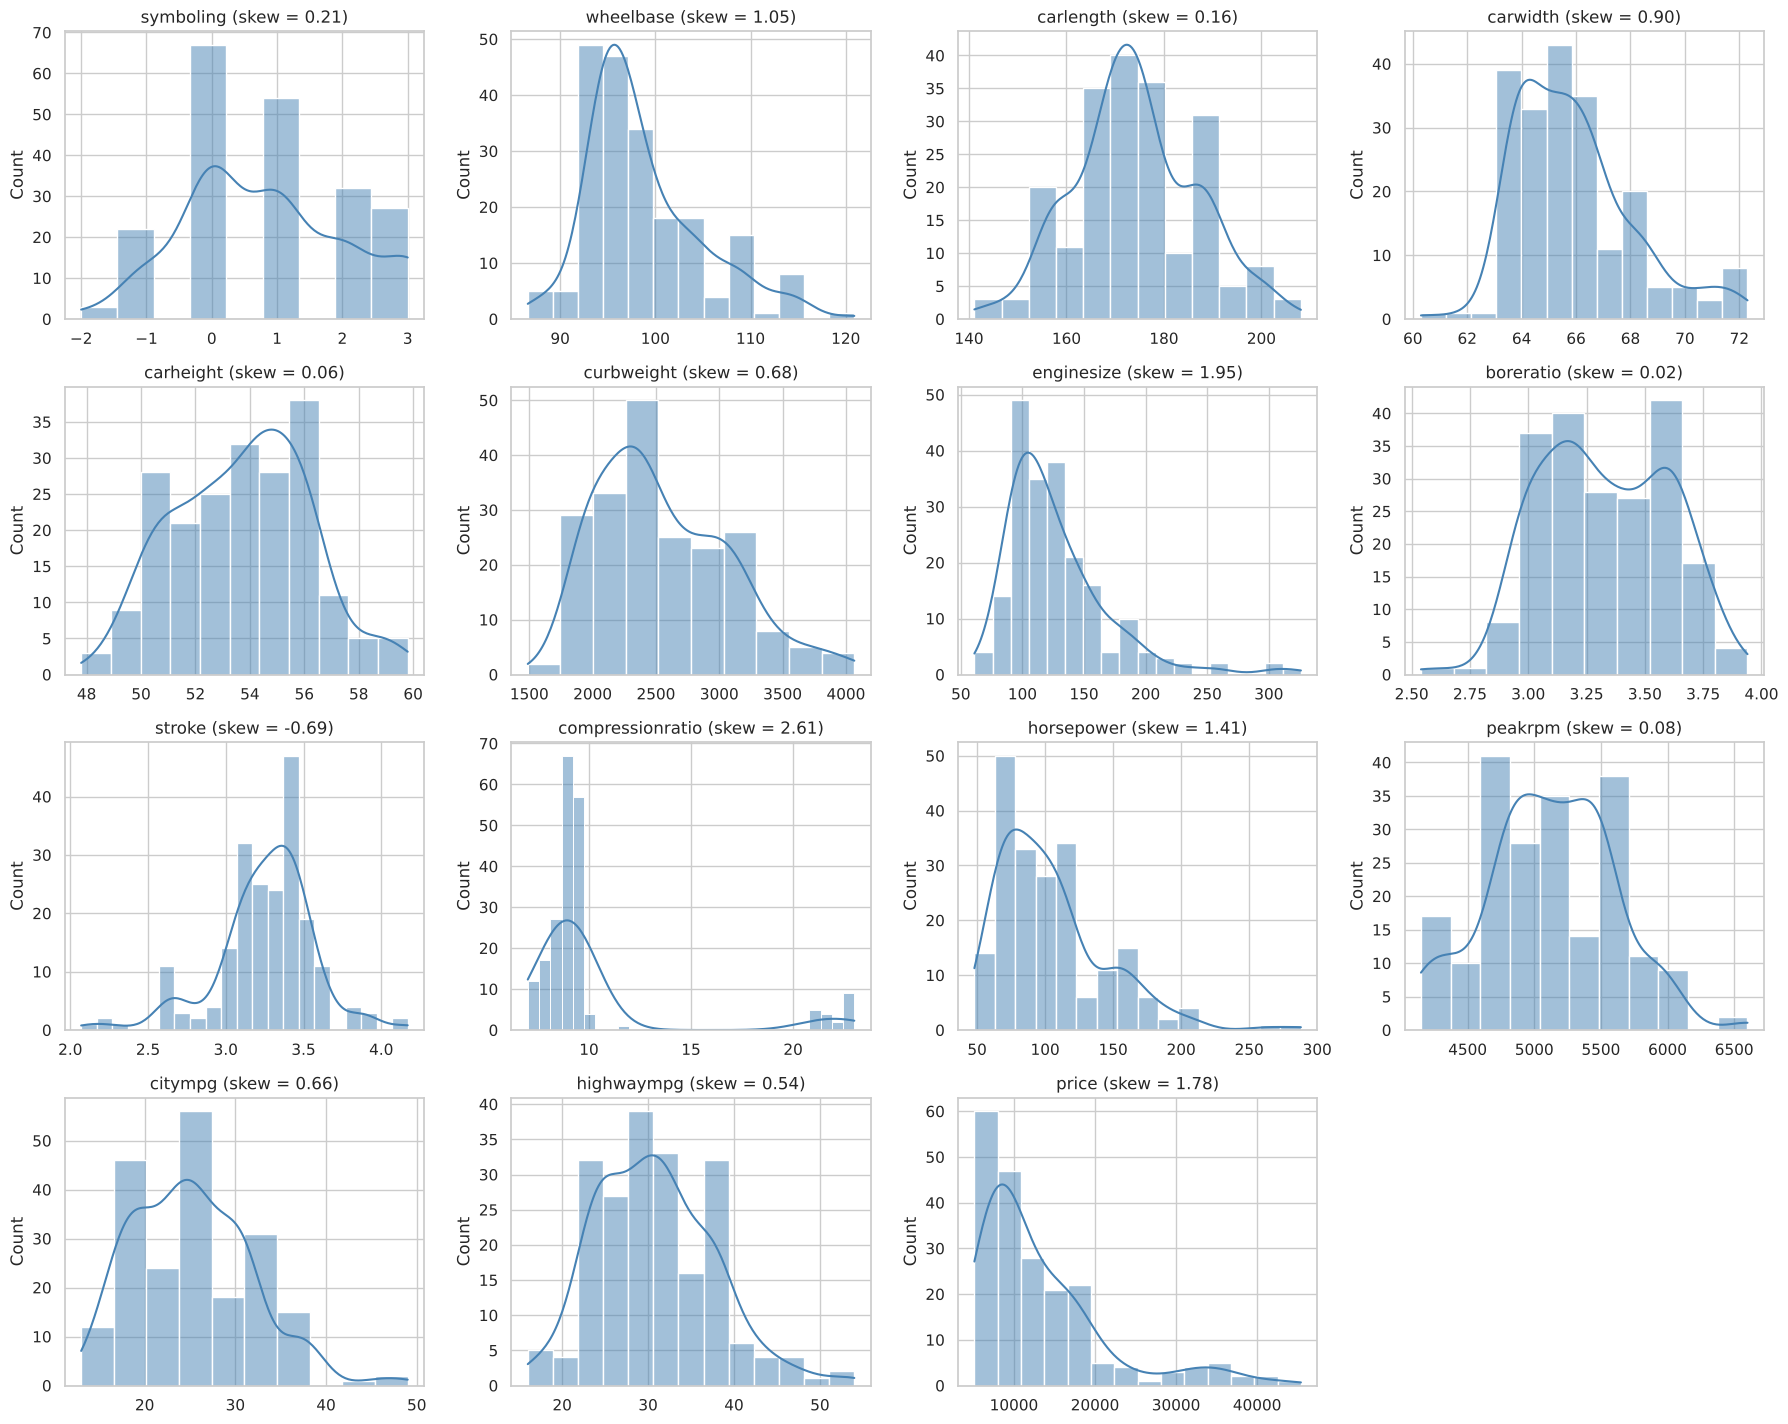


Коефіцієнти асиметрії (за модулем, від найбільшої):


,skewness
compressionratio,2.610862
enginesize,1.947655
price,1.777678
horsepower,1.405310
wheelbase,1.050214
carwidth,0.904003
stroke,-0.689705
curbweight,0.681398
citympg,0.663704
highwaympg,0.539997


Ознаки з найбільш вираженою асиметрією:
compressionratio    2.611
enginesize          1.948
price               1.778
horsepower          1.405
wheelbase           1.050

Висновок: найсильніше асиметричні (правосторонні) ознаки - compressionratio (2.61), enginesize (1.95), price (1.78), horsepower (1.41); вони мають довгий правий хвіст (дорогі/потужні авто та дизелі). Більшість інших ознак помірно асиметричні. Це обґрунтовує застосування Yeo-Johnson перетворення.


In [4]:
numeric_cols = data.select_dtypes(include="number").columns.tolist()
print("Числові ознаки:", numeric_cols)

# Гістограми з KDE
n_cols = 4
n_rows = int(np.ceil(len(numeric_cols) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, 3.6 * n_rows))
for ax, col in zip(axes.ravel(), numeric_cols):
    sns.histplot(data[col], kde=True, ax=ax, color="steelblue")
    ax.set_title(f"{col} (skew = {data[col].skew():.2f})")
    ax.set_xlabel("")
for ax in axes.ravel()[len(numeric_cols):]:
    ax.axis("off")
plt.tight_layout()
plt.show()

# Коефіцієнти асиметрії
skew_all = data[numeric_cols].skew().sort_values(key=np.abs, ascending=False)
print("\nКоефіцієнти асиметрії (за модулем, від найбільшої):")
display(skew_all.to_frame("skewness"))

print("Ознаки з найбільш вираженою асиметрією:")
print(skew_all.head(5).round(3).to_string())

print("\nВисновок: найсильніше асиметричні (правосторонні) ознаки - compressionratio (2.61), enginesize (1.95), "
      "price (1.78), horsepower (1.41); вони мають довгий правий хвіст (дорогі/потужні авто та дизелі). "
      "Більшість інших ознак помірно асиметричні. Це обґрунтовує застосування Yeo-Johnson перетворення.")


## 5. Формування train/test вибірок

Відокремити цільову змінну `price` від ознак та розділити дані на:
- навчальну вибірку — 80%;
- тестову вибірку — 20%.

Забезпечити відтворюваність поділу.  
Окремо зберегти `car_ID` для об'єктів, які потрапили до train і test.

**Важливо:** усі подальші параметри передобробки даних визначати тільки за навчальною вибіркою.


In [5]:
X = data.drop(columns="price")
y = data["price"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)

# car_ID для об'єктів train і test (індекси збігаються з X_train / X_test)
ids_train = car_ids.loc[X_train.index]
ids_test = car_ids.loc[X_test.index]

print(f"Train: {X_train.shape[0]} об'єктів ({X_train.shape[0] / len(X):.0%})")
print(f"Test:  {X_test.shape[0]} об'єктів ({X_test.shape[0] / len(X):.0%})")
print("Ознак:", X_train.shape[1])
print("Перетину train/test немає:", set(ids_train).isdisjoint(set(ids_test)))
print(f"\nСередня ціна: train = {y_train.mean():.0f}, test = {y_test.mean():.0f}")

print("Висновок: дані розділено у співвідношенні 80/20 з фіксованим random_state=42 (поділ відтворюваний). "
      "car_ID збережено окремо для train і test, розподіл цін у вибірках приблизно однаковий.")


Train: 164 об'єктів (80%)
Test:  41 об'єктів (20%)
Ознак: 24
Перетину train/test немає: True

Середня ціна: train = 13223, test = 13490
Висновок: дані розділено у співвідношенні 80/20 з фіксованим random_state=42 (поділ відтворюваний). car_ID збережено окремо для train і test, розподіл цін у вибірках приблизно однаковий.


## 6. Аналіз та обробка викидів

Для неперервних числових ознак навчальної вибірки:
- визначити потенційні викиди методом IQR;
- вивести кількість потенційних викидів для кожної ознаки;
- обґрунтувати спосіб їх обробки.

Для невеликого набору даних не видаляти автоматично всі рядки з викидами. Використати обмеження крайніх значень межами, визначеними за навчальною вибіркою.

Цільову змінну `price` не використовувати для визначення меж викидів.  
До тестової вибірки застосувати ті самі межі, які були отримані за train.


In [6]:
continuous_features = ["wheelbase", "carlength", "carwidth", "carheight", "curbweight",
                       "enginesize", "boreratio", "stroke", "compressionratio",
                       "horsepower", "peakrpm", "citympg", "highwaympg"]

# Копія train до обробки викидів - знадобиться для порівняння асиметрії у п. 9
X_train_raw = X_train.copy()

# Межі IQR визначаються ТІЛЬКИ за train; price у розрахунку не використовується
q1 = X_train[continuous_features].quantile(0.25)
q3 = X_train[continuous_features].quantile(0.75)
iqr = q3 - q1
lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

outlier_report = pd.DataFrame({
    "lower": lower_bound,
    "upper": upper_bound,
    "n_below": (X_train[continuous_features] < lower_bound).sum(),
    "n_above": (X_train[continuous_features] > upper_bound).sum(),
})
outlier_report["n_outliers"] = outlier_report["n_below"] + outlier_report["n_above"]
outlier_report["share_%"] = (outlier_report["n_outliers"] / len(X_train) * 100).round(2)
print("Потенційні викиди (метод IQR, межі за train):")
display(outlier_report.sort_values("n_outliers", ascending=False))

# Обробка: обмеження (winsorization) крайніх значень межами з train; рядки не видаляються
X_train[continuous_features] = X_train[continuous_features].clip(lower_bound, upper_bound, axis=1)
X_test[continuous_features] = X_test[continuous_features].clip(lower_bound, upper_bound, axis=1)

print("Викидів у train після обробки:",
      int(((X_train[continuous_features] < lower_bound) | (X_train[continuous_features] > upper_bound)).sum().sum()))
n_test_clipped = int(((X.loc[X_test.index, continuous_features] < lower_bound)
                      | (X.loc[X_test.index, continuous_features] > upper_bound)).sum().sum())
print("Кількість значень test, обмежених межами train:", n_test_clipped)

print("Висновок: викиди у більшості ознак нечисленні. Оскільки вибірка мала (205 авто), а частина "
      "викидів - це реальні дорогі/потужні моделі, видаляти рядки недоцільно: це зменшило б дані й "
      "змістило розподіл. Тому крайні значення обмежено межами IQR, обчисленими лише за train, "
      "і ті самі межі застосовано до test.")


Потенційні викиди (метод IQR, межі за train):


,lower,upper,n_below,n_above,n_outliers,share_%
compressionratio,7.4000,10.6000,4,16,20,12.20
stroke,2.6600,3.8600,11,5,16,9.76
carwidth,60.4250,70.4250,0,10,10,6.10
horsepower,4.7500,182.7500,0,7,7,4.27
enginesize,33.5000,205.5000,0,7,7,4.27
wheelbase,83.1000,113.5000,0,6,6,3.66
peakrpm,3750.0000,6550.0000,0,2,2,1.22
highwaympg,11.5000,47.5000,0,1,1,0.61
boreratio,2.5650,4.1250,1,0,1,0.61
curbweight,998.6250,4103.6250,0,0,0,0.00


Викидів у train після обробки: 0
Кількість значень test, обмежених межами train: 25
Висновок: викиди у більшості ознак нечисленні. Оскільки вибірка мала (205 авто), а частина викидів - це реальні дорогі/потужні моделі, видаляти рядки недоцільно: це зменшило б дані й змістило розподіл. Тому крайні значення обмежено межами IQR, обчисленими лише за train, і ті самі межі застосовано до test.


## 7. Аналіз кореляцій та відбір ознак

За навчальною вибіркою:
- побудувати матрицю кореляцій числових ознак;
- знайти пари ознак із сильною кореляцією, для яких `|r| > 0.85`;
- для кожної такої пари залишити одну ознаку;
- під час вибору врахувати силу зв'язку кожної ознаки з цільовою змінною `price`;
- вивести список сильно корельованих пар та перелік ознак, які видаляються.

Із тестової вибірки видалити ті самі ознаки.  
Не використовувати тестову вибірку для прийняття рішення про відбір ознак.


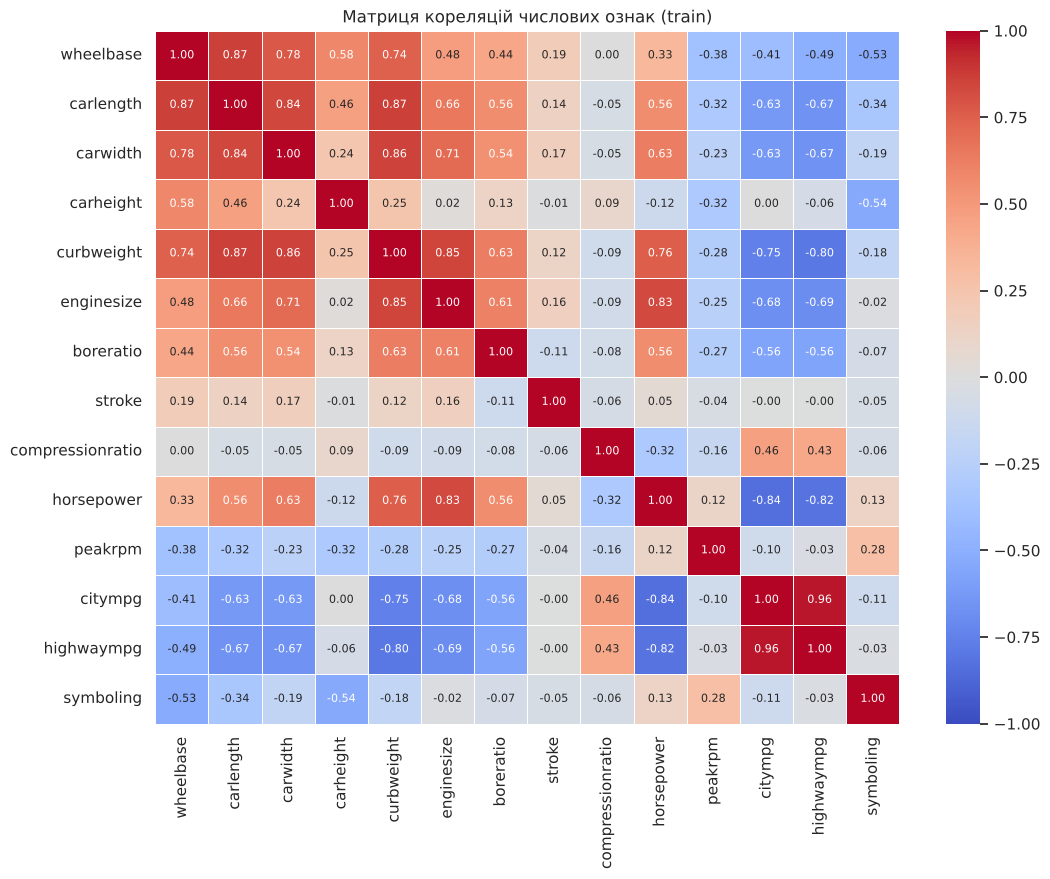

Сила зв'язку ознак з price (|r|, train):
enginesize          0.846
curbweight          0.824
horsepower          0.807
carwidth            0.732
highwaympg          0.716
citympg             0.711
carlength           0.652
boreratio           0.547
wheelbase           0.504
peakrpm             0.070
compressionratio    0.060
carheight           0.044
stroke              0.006
symboling           0.005

Пар із |r| > 0.85: 4


,feature_1,feature_2,r,|r| з price (1),|r| з price (2),залишено,видалено,примітка
0,citympg,highwaympg,0.964,0.711,0.716,highwaympg,citympg,видалено нову ознаку
1,wheelbase,carlength,0.867,0.504,0.652,carlength,wheelbase,видалено нову ознаку
2,carlength,curbweight,0.866,0.652,0.824,curbweight,carlength,видалено нову ознаку
3,carwidth,curbweight,0.858,0.732,0.824,curbweight,carwidth,видалено нову ознаку


Ознаки, які видаляються: ['citympg', 'wheelbase', 'carlength', 'carwidth']
Ознак після відбору: 20
Висновок: розміри кузова, вага, об'єм двигуна, потужність і витрата пального сильно корелюють між собою (мультиколінеарність). З кожної пари залишено ознаку з сильнішим зв'язком із price, а надлишкові ознаки видалено; рішення ухвалено лише за train.


In [7]:
numeric_features = continuous_features + ["symboling"]

corr = X_train[numeric_features].corr()
target_corr = X_train[numeric_features].corrwith(y_train).abs().sort_values(ascending=False)

plt.figure(figsize=(12, 9))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1,
            linewidths=0.4, annot_kws={"size": 8})
plt.title("Матриця кореляцій числових ознак (train)")
plt.show()

print("Сила зв'язку ознак з price (|r|, train):")
print(target_corr.round(3).to_string())

# Пари із сильною кореляцією |r| > 0.85
threshold = 0.85
pairs = []
for i, a in enumerate(numeric_features):
    for b in numeric_features[i + 1:]:
        if abs(corr.loc[a, b]) > threshold:
            pairs.append((a, b, corr.loc[a, b]))
pairs.sort(key=lambda t: -abs(t[2]))

# Для кожної пари залишаємо ознаку, сильніше пов'язану з price
to_drop = []
rows = []
for a, b, r in pairs:
    if a in to_drop or b in to_drop:
        decision = "пару вже розв'язано"
        dropped = a if a in to_drop else b
    else:
        dropped = a if target_corr[a] < target_corr[b] else b
        to_drop.append(dropped)
        decision = "видалено нову ознаку"
    kept = b if dropped == a else a
    rows.append({"feature_1": a, "feature_2": b, "r": round(r, 3),
                 "|r| з price (1)": round(target_corr[a], 3),
                 "|r| з price (2)": round(target_corr[b], 3),
                 "залишено": kept, "видалено": dropped, "примітка": decision})

print(f"\nПар із |r| > {threshold}: {len(pairs)}")
display(pd.DataFrame(rows))
print("Ознаки, які видаляються:", to_drop)

X_train = X_train.drop(columns=to_drop)
X_test = X_test.drop(columns=to_drop)
print("Ознак після відбору:", X_train.shape[1])

print("Висновок: розміри кузова, вага, об'єм двигуна, потужність і витрата пального сильно корелюють між "
      "собою (мультиколінеарність). З кожної пари залишено ознаку з сильнішим зв'язком із price, "
      "а надлишкові ознаки видалено; рішення ухвалено лише за train.")


## 8. Підготовка числових і категоріальних ознак

Розділити ознаки на:
- неперервні числові;
- дискретну числову ознаку `symboling`;
- категоріальні.

Для неперервних числових ознак виконати послідовно:
1. перетворення Yeo–Johnson для зменшення асиметрії;
2. масштабування за допомогою StandardScaler.

Для `symboling` виконати масштабування без Yeo–Johnson.

Категоріальні ознаки закодувати методом One-Hot Encoding. Передбачити коректну обробку категорій у test, яких не було у train.

Усі перетворення об'єднати в єдиний механізм передобробки даних, який навчається тільки на `X_train`.


In [8]:
continuous = [c for c in continuous_features if c in X_train.columns]
discrete = ["symboling"]
categorical = X_train.select_dtypes(include="object").columns.tolist()

print("Неперервні числові:", continuous)
print("Дискретна числова:", discrete)
print("Категоріальні:", categorical)

preprocessor = ColumnTransformer(
    transformers=[
        ("num_cont", Pipeline([
            ("yeo_johnson", PowerTransformer(method="yeo-johnson", standardize=False)),
            ("scaler", StandardScaler()),
        ]), continuous),
        ("num_disc", StandardScaler(), discrete),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical),
    ],
    remainder="drop",
)

# Навчання передобробки тільки на X_train
preprocessor.fit(X_train)

feature_names = preprocessor.get_feature_names_out()
print("\nКількість ознак після передобробки:", len(feature_names))
print("Форма X_train після передобробки:", preprocessor.transform(X_train).shape)
print("Форма X_test після передобробки: ", preprocessor.transform(X_test).shape)

print("Висновок: створено єдиний ColumnTransformer: Yeo-Johnson + StandardScaler для неперервних, "
      "StandardScaler для symboling, One-Hot (handle_unknown='ignore') для категоріальних. "
      "Параметри передобробки визначені лише за X_train; невідомі в train категорії в test не викликають помилки.")


Неперервні числові: ['carheight', 'curbweight', 'enginesize', 'boreratio', 'stroke', 'compressionratio', 'horsepower', 'peakrpm', 'highwaympg']
Дискретна числова: ['symboling']
Категоріальні: ['fueltype', 'aspiration', 'doornumber', 'carbody', 'drivewheel', 'enginelocation', 'enginetype', 'cylindernumber', 'fuelsystem', 'brand']

Кількість ознак після передобробки: 69
Форма X_train після передобробки: (164, 69)
Форма X_test після передобробки:  (41, 69)
Висновок: створено єдиний ColumnTransformer: Yeo-Johnson + StandardScaler для неперервних, StandardScaler для symboling, One-Hot (handle_unknown='ignore') для категоріальних. Параметри передобробки визначені лише за X_train; невідомі в train категорії в test не викликають помилки.


## 9. Перевірка трансформації числових ознак

Перевірити результат трансформації неперервних числових ознак:
- застосувати до train ту саму послідовність перетворень, яка буде використана в моделях;
- повторно обчислити коефіцієнти асиметрії;
- порівняти їх із початковими значеннями;
- зробити короткий висновок щодо ефективності трансформації.


,"до обробки (train, сирі)",після IQR-обмеження,після Yeo-Johnson + Scaler,|skew| зменшилась
carheight,0.028,0.028,-0.005,True
curbweight,0.712,0.712,0.050,True
enginesize,2.050,0.962,0.045,True
boreratio,0.050,0.063,-0.006,True
stroke,-0.755,-0.398,0.016,True
compressionratio,2.737,0.056,0.005,True
horsepower,1.546,0.851,0.066,True
peakrpm,0.067,0.040,-0.004,True
highwaympg,0.290,0.244,-0.012,True


Середня |skew| до:    0.915
Середня |skew| після: 0.023
Ознак зі зменшеною |skew|: 9 з 9


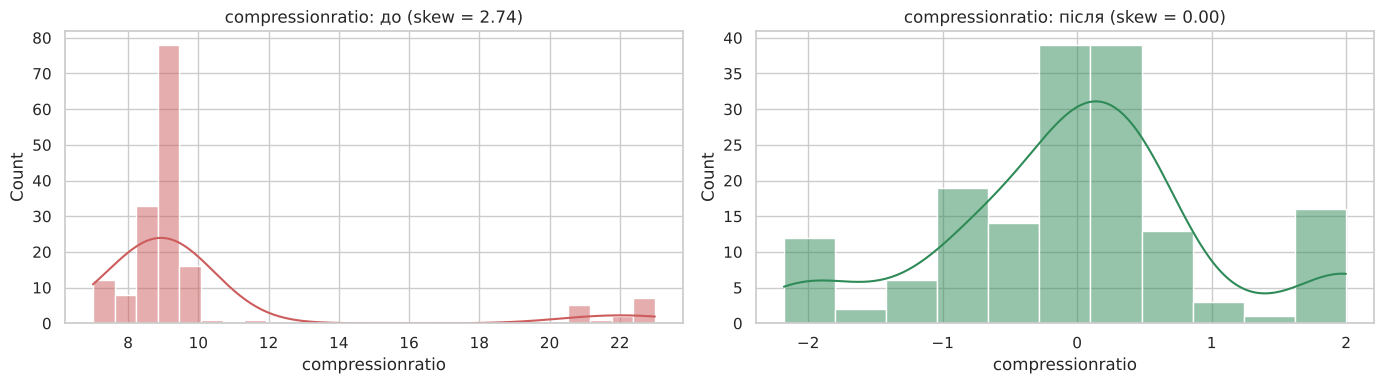

Висновок: Yeo-Johnson + StandardScaler суттєво зменшили асиметрію: середня |skew| знизилась з 0.915 до 0.023, а у всіх 9 неперервних ознак |skew| зменшилась. Найбільший ефект - у enginesize (2.05 -> 0.05), compressionratio (2.74 -> 0.005) та horsepower (1.55 -> 0.07); частину цього ефекту для compressionratio і enginesize дало й попереднє обмеження викидів. Для ознак, що й так були симетричними (carheight, boreratio, peakrpm), зміна незначна. Трансформація ефективна.


In [9]:
cont_transformer = preprocessor.named_transformers_["num_cont"]

X_train_cont_t = pd.DataFrame(
    cont_transformer.transform(X_train[continuous]), columns=continuous, index=X_train.index
)

skew_compare = pd.DataFrame({
    "до обробки (train, сирі)": X_train_raw[continuous].skew(),
    "після IQR-обмеження": X_train[continuous].skew(),
    "після Yeo-Johnson + Scaler": X_train_cont_t.skew(),
}).round(3)
skew_compare["|skew| зменшилась"] = (
    skew_compare["після Yeo-Johnson + Scaler"].abs() < skew_compare["до обробки (train, сирі)"].abs()
)
display(skew_compare)

print("Середня |skew| до:   ", round(skew_compare["до обробки (train, сирі)"].abs().mean(), 3))
print("Середня |skew| після:", round(skew_compare["після Yeo-Johnson + Scaler"].abs().mean(), 3))
print("Ознак зі зменшеною |skew|:", int(skew_compare["|skew| зменшилась"].sum()), "з", len(continuous))

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
worst = X_train_raw[continuous].skew().abs().idxmax()
sns.histplot(X_train_raw[worst], kde=True, ax=axes[0], color="indianred")
axes[0].set_title(f"{worst}: до (skew = {X_train_raw[worst].skew():.2f})")
sns.histplot(X_train_cont_t[worst], kde=True, ax=axes[1], color="seagreen")
axes[1].set_title(f"{worst}: після (skew = {X_train_cont_t[worst].skew():.2f})")
plt.tight_layout()
plt.show()

print("Висновок: Yeo-Johnson + StandardScaler суттєво зменшили асиметрію: середня |skew| знизилась з 0.915 до 0.023, "
      "а у всіх 9 неперервних ознак |skew| зменшилась. Найбільший ефект - у enginesize (2.05 -> 0.05), "
      "compressionratio (2.74 -> 0.005) та horsepower (1.55 -> 0.07); частину цього ефекту для compressionratio "
      "і enginesize дало й попереднє обмеження викидів. Для ознак, що й так були симетричними (carheight, boreratio, "
      "peakrpm), зміна незначна. Трансформація ефективна.")


## 10. Побудова регресійних моделей

Побудувати та навчити такі моделі:
- Linear Regression;
- Ridge Regression;
- Lasso Regression;
- Random Forest Regressor;
- Gradient Boosting Regressor;
- Support Vector Regressor (SVR).

Для кожної моделі створити єдиний Pipeline, який містить:
1. попередню обробку ознак;
2. відповідну регресійну модель.

Використати однакову схему підготовки даних для коректного порівняння моделей.


In [10]:
# Гіперпараметри Ridge (alpha), Lasso (alpha) та SVR (C, epsilon) підібрано GridSearchCV (5-fold) лише на train
models = {
    "Linear Regression": LinearRegression(),
    "Ridge Regression": Ridge(alpha=0.3, random_state=RANDOM_STATE),
    "Lasso Regression": Lasso(alpha=10.0, max_iter=50000, random_state=RANDOM_STATE),
    "Random Forest": RandomForestRegressor(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1),
    "Gradient Boosting": GradientBoostingRegressor(n_estimators=300, learning_rate=0.05, max_depth=3,
                                                   random_state=RANDOM_STATE),
    "SVR": SVR(kernel="rbf", C=300000, epsilon=500),
}

# Єдина схема передобробки для всіх моделей: clone(...) дає кожному Pipeline власну копію
pipelines = {
    name: Pipeline([("preprocessor", clone(preprocessor)), ("model", model)])
    for name, model in models.items()
}

for name, pipe in pipelines.items():
    print(f"{name:20s} -> {[step for step, _ in pipe.steps]}")

print("Висновок: для 6 моделей створено Pipeline однакової структури (передобробка + модель). "
      "Передобробка всередині Pipeline навчається лише на тому, на чому викликається fit (на X_train), "
      "тож порівняння моделей коректне.")


Linear Regression    -> ['preprocessor', 'model']
Ridge Regression     -> ['preprocessor', 'model']
Lasso Regression     -> ['preprocessor', 'model']
Random Forest        -> ['preprocessor', 'model']
Gradient Boosting    -> ['preprocessor', 'model']
SVR                  -> ['preprocessor', 'model']
Висновок: для 6 моделей створено Pipeline однакової структури (передобробка + модель). Передобробка всередині Pipeline навчається лише на тому, на чому викликається fit (на X_train), тож порівняння моделей коректне.


## 11. Оцінювання якості моделей

Для кожної моделі:
- виконати навчання на тренувальній вибірці;
- отримати прогноз для тестової вибірки;
- обчислити метрики **R², MAE, MSE та MAPE**.

`MAPE` подати у відсотках.

Результати всіх моделей об'єднати в одну порівняльну таблицю та впорядкувати за значенням R² від найбільшого до найменшого.

Під час інтерпретації врахувати:
- R² — чим більше, тим краще;
- MAE, MSE, MAPE — чим менше, тим краще.


In [11]:
def evaluate(y_true, y_pred):
    return {
        "R2": r2_score(y_true, y_pred),
        "MAE": mean_absolute_error(y_true, y_pred),
        "MSE": mean_squared_error(y_true, y_pred),
        "MAPE, %": mean_absolute_percentage_error(y_true, y_pred) * 100,
    }

results = []
predictions = {}
train_r2 = {}

for name, pipe in pipelines.items():
    pipe.fit(X_train, y_train)                 # навчання на train
    y_pred = pipe.predict(X_test)              # прогноз для test
    predictions[name] = y_pred
    train_r2[name] = r2_score(y_train, pipe.predict(X_train))
    results.append({"Model": name, **evaluate(y_test, y_pred)})

results_df = (pd.DataFrame(results)
              .sort_values("R2", ascending=False)
              .reset_index(drop=True))
display(results_df.round({"R2": 4, "MAE": 1, "MSE": 0, "MAPE, %": 2}))

# Для аналізу перенавчання: R2 на train проти R2 на test
overfit_df = pd.DataFrame({
    "R2 train": pd.Series(train_r2),
    "R2 test": results_df.set_index("Model")["R2"],
})
overfit_df["різниця"] = overfit_df["R2 train"] - overfit_df["R2 test"]
print("\nПорівняння R2 на train і test (діагностика перенавчання):")
display(overfit_df.sort_values("R2 test", ascending=False).round(4))

print("\nВисновок: найкращою за всіма метриками є Random Forest (R² = 0.955, MAE ≈ 1311, MSE ≈ 3.52 млн, MAPE ≈ 9.6%). "
      "Далі йдуть SVR (R² = 0.938) і Gradient Boosting (R² = 0.931), а лінійні моделі (Linear, Ridge, Lasso) "
      "слабші (R² = 0.85-0.88, MAPE 16-17%).")


,Model,R2,MAE,MSE,"MAPE, %"
0,Random Forest,0.9554,1311.1,3519785.0,9.64
1,SVR,0.9375,1565.5,4933032.0,13.86
2,Gradient Boosting,0.9306,1694.4,5481450.0,11.48
3,Linear Regression,0.8794,2156.1,9518236.0,16.38
4,Ridge Regression,0.8690,2190.8,10342865.0,15.82
5,Lasso Regression,0.8504,2350.4,11807240.0,17.38



Порівняння R2 на train і test (діагностика перенавчання):


,R2 train,R2 test,різниця
Random Forest,0.9851,0.9554,0.0297
SVR,0.9917,0.9375,0.0542
Gradient Boosting,0.9957,0.9306,0.0651
Linear Regression,0.9597,0.8794,0.0803
Ridge Regression,0.9570,0.8690,0.0880
Lasso Regression,0.9529,0.8504,0.1025



Висновок: найкращою за всіма метриками є Random Forest (R² = 0.955, MAE ≈ 1311, MSE ≈ 3.52 млн, MAPE ≈ 9.6%). Далі йдуть SVR (R² = 0.938) і Gradient Boosting (R² = 0.931), а лінійні моделі (Linear, Ridge, Lasso) слабші (R² = 0.85-0.88, MAPE 16-17%).


## 12. Пояснення вибору типу моделі

Пояснити, чому класифікаційна модель, наприклад Logistic Regression, не підходить для безпосереднього прогнозування неперервної ціни автомобіля.

Зазначити, до якого типу задачі належить прогнозування `price` та чому моделі, використані в роботі, відповідають цій задачі.


**Чому Logistic Regression не підходить.** Logistic Regression - це класифікаційна модель: вона оцінює ймовірності належності об'єкта до скінченної множини класів (на виході клас або ймовірність від 0 до 1). Ціна автомобіля `price` - неперервна величина, яка може набувати практично будь-якого значення в діапазоні (у даних від 5118 до 45400), тому її не можна подати як невелику кількість класів без втрати інформації. Якщо ж розбити ціну на інтервали, модель покаже лише цінову категорію, а не конкретну суму, і втратиться змістовна міра похибки (у доларах чи відсотках).

**Тип задачі.** Прогнозування `price` - це задача **регресії** (навчання з учителем із неперервною цільовою змінною).

**Чому використані моделі підходять.** Linear, Ridge і Lasso Regression моделюють цільову змінну як лінійну функцію ознак (Ridge і Lasso додають L2- та L1-регуляризацію, що допомагає за мультиколінеарності та великої кількості ознак після One-Hot кодування). Random Forest Regressor і Gradient Boosting Regressor - ансамблі дерев рішень, які передбачають неперервне значення (усереднення по деревах) і вловлюють нелінійні залежності та взаємодії ознак. SVR - регресійна версія методу опорних векторів з ядром, яка також повертає неперервний прогноз. Усі ці моделі мінімізують помилку між фактичним і прогнозованим числом, тому оцінюються регресійними метриками (R², MAE, MSE, MAPE).

## 13. Візуальне порівняння прогнозів

Для кожної побудованої моделі зобразити співвідношення:
- фактичних значень `price`;
- прогнозованих значень `price`.

Додати лінію ідеального прогнозу та проаналізувати, наскільки близько до неї розташовані прогнозовані значення. Звернути увагу на великі відхилення.


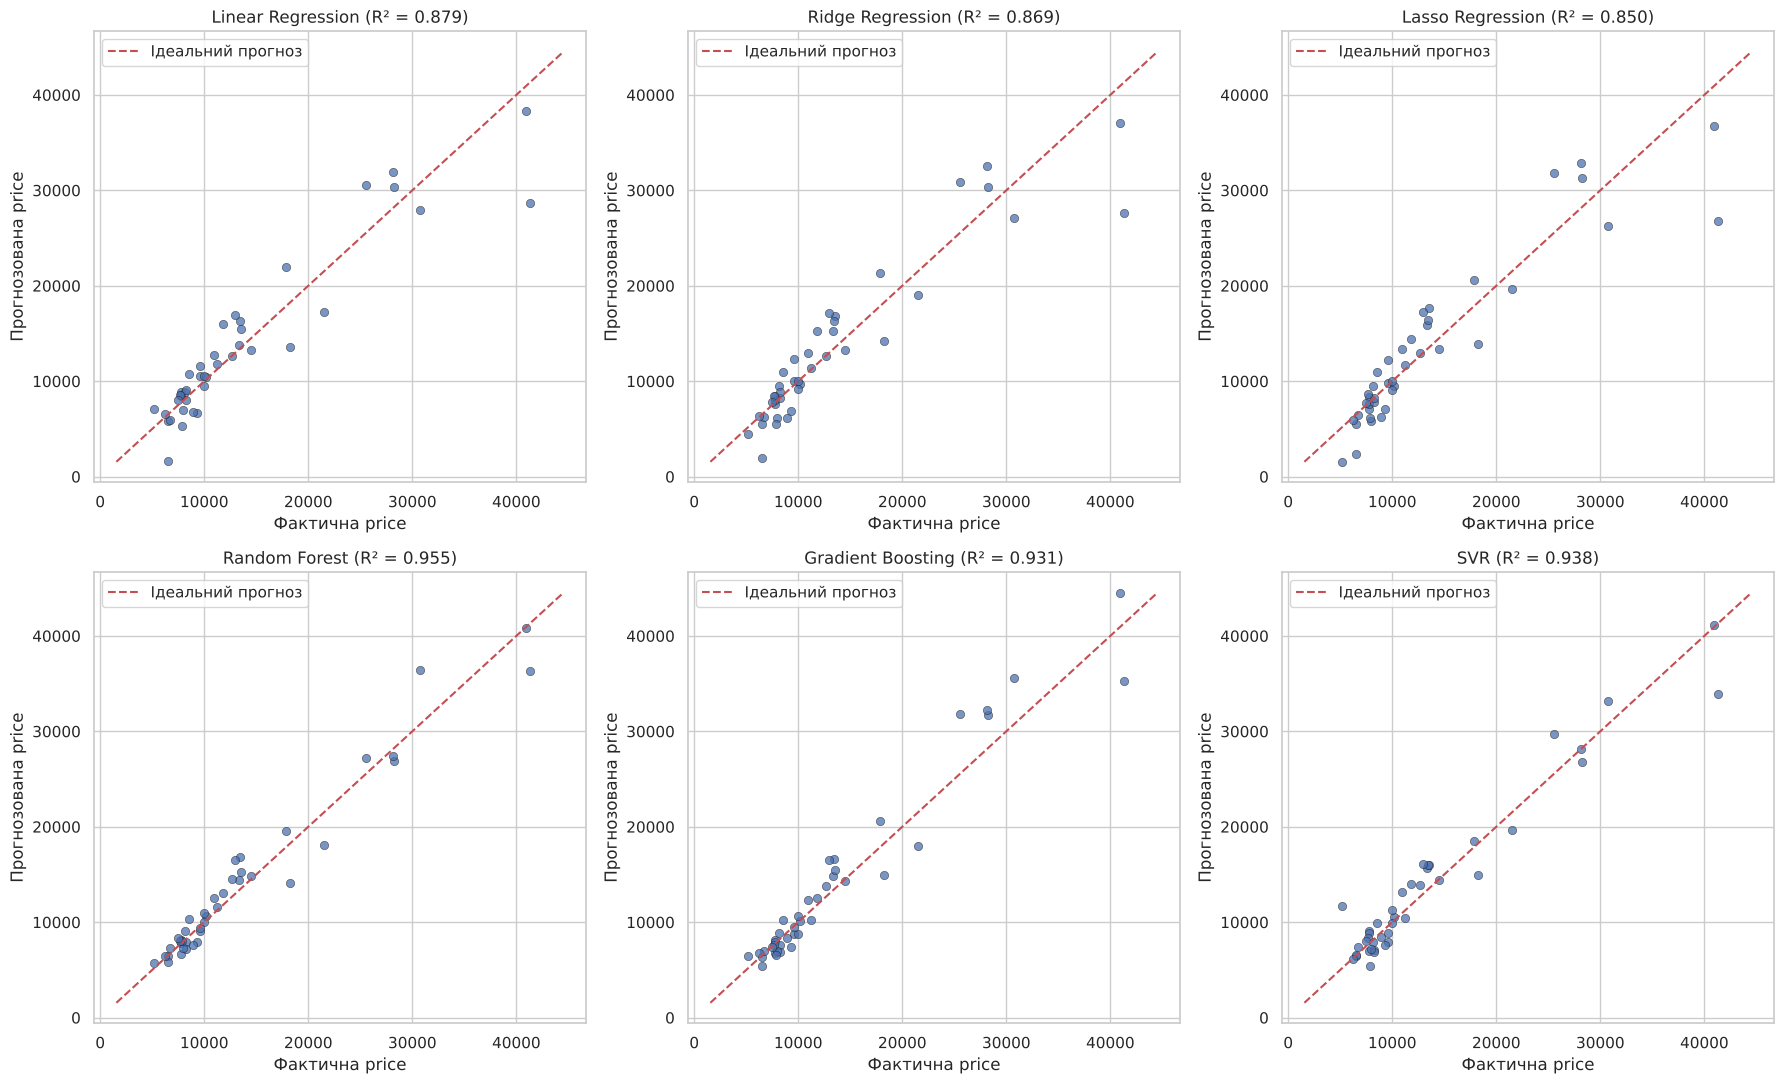

Linear Regression    найбільша помилка:    12681 (car_ID = 17, факт = 41315, прогноз = 28634)
Ridge Regression     найбільша помилка:    13683 (car_ID = 17, факт = 41315, прогноз = 27632)
Lasso Regression     найбільша помилка:    14572 (car_ID = 17, факт = 41315, прогноз = 26743)
Random Forest        найбільша помилка:     5623 (car_ID = 16, факт = 30760, прогноз = 36383)
Gradient Boosting    найбільша помилка:     6313 (car_ID = 68, факт = 25552, прогноз = 31865)
SVR                  найбільша помилка:     7383 (car_ID = 17, факт = 41315, прогноз = 33932)

Висновок: точки Random Forest, Gradient Boosting і SVR розташовані найближче до лінії ідеального прогнозу. Лінійні моделі систематично занижують ціну дорогих авто (напр., car_ID = 17: факт 41315, прогноз ≈ 27-29 тис.), тобто зв'язок ознак із ціною нелінійний. Найбільші відхилення в усіх моделей припадають на верхній ціновий сегмент, де у вибірці мало спостережень.


In [12]:
fig, axes = plt.subplots(2, 3, figsize=(18, 11))
lims = [min(y_test.min(), min(p.min() for p in predictions.values())),
        max(y_test.max(), max(p.max() for p in predictions.values()))]

for ax, (name, y_pred) in zip(axes.ravel(), predictions.items()):
    ax.scatter(y_test, y_pred, alpha=0.75, edgecolor="k", linewidth=0.4)
    ax.plot(lims, lims, "r--", label="Ідеальний прогноз")
    r2 = r2_score(y_test, y_pred)
    ax.set_title(f"{name} (R² = {r2:.3f})")
    ax.set_xlabel("Фактична price")
    ax.set_ylabel("Прогнозована price")
    ax.legend()

plt.tight_layout()
plt.show()

# Найбільші відхилення для кожної моделі
for name, y_pred in predictions.items():
    err = (y_test - y_pred).abs().sort_values(ascending=False)
    top = err.index[0]
    print(f"{name:20s} найбільша помилка: {err.iloc[0]:8.0f} "
          f"(car_ID = {car_ids.loc[top]}, факт = {y_test.loc[top]:.0f}, прогноз = {pd.Series(y_pred, index=y_test.index).loc[top]:.0f})")

print("\nВисновок: точки Random Forest, Gradient Boosting і SVR розташовані найближче до лінії ідеального прогнозу. "
      "Лінійні моделі систематично занижують ціну дорогих авто (напр., car_ID = 17: факт 41315, прогноз ≈ 27-29 тис.), "
      "тобто зв'язок ознак із ціною нелінійний. Найбільші відхилення в усіх моделей припадають на верхній ціновий "
      "сегмент, де у вибірці мало спостережень.")


## 14. Прогноз для 10 автомобілів

Випадково вибрати 10 автомобілів із тестової вибірки.

За допомогою моделі Random Forest отримати для них прогноз ціни та сформувати таблицю з такими даними:
- `car_ID`;
- фактична ціна;
- прогнозована ціна;
- абсолютна помилка;
- абсолютна відсоткова помилка.

Прокоментувати отримані результати.


In [13]:
rf_pipe = pipelines["Random Forest"]

sample_idx = X_test.sample(n=10, random_state=RANDOM_STATE).index
y_true_s = y_test.loc[sample_idx]
y_pred_s = pd.Series(rf_pipe.predict(X_test.loc[sample_idx]), index=sample_idx)

sample_table = pd.DataFrame({
    "car_ID": car_ids.loc[sample_idx].values,
    "Фактична ціна": y_true_s.values,
    "Прогнозована ціна": y_pred_s.values.round(2),
    "Абсолютна помилка": (y_true_s - y_pred_s).abs().values.round(2),
    "Абс. відсоткова помилка, %": ((y_true_s - y_pred_s).abs() / y_true_s * 100).values.round(2),
}).reset_index(drop=True)

display(sample_table)
print("Середня абсолютна помилка по вибірці:", round(sample_table["Абсолютна помилка"].mean(), 2))
print("Середня абс. відсоткова помилка, %:", round(sample_table["Абс. відсоткова помилка, %"].mean(), 2))

print("\nВисновок: середня абсолютна помилка по 10 авто становить ≈ 1329, середня відсоткова ≈ 8.3%; "
      "для 9 з 10 авто помилка не перевищує 12%, а для кількох - менша за 3%. Найбільше відхилення - у car_ID = 195 "
      "(факт 12940, прогноз ≈ 16563, ≈ 28%): модель переоцінила автомобіль, подібний до дорожчих моделей тієї ж марки. "
      "У найдорожчого авто (car_ID = 17) похибка в грошах найбільша (≈ 4946), але у відсотках помірна (≈ 12%). "
      "Вибірка з 10 об'єктів мала, тому це лише ілюстрація якості, а не заміна оцінки на всьому test.")


,car_ID,Фактична ціна,Прогнозована ціна,Абсолютна помилка,"Абс. відсоткова помилка, %"
0,26,6692.0,7322.24,630.24,9.42
1,176,9988.0,10929.02,941.02,9.42
2,148,10198.0,10695.45,497.45,4.88
3,17,41315.0,36368.71,4946.29,11.97
4,69,28248.0,26909.69,1338.31,4.74
5,147,7463.0,8294.29,831.29,11.14
6,144,9960.0,10062.71,102.71,1.03
7,85,14489.0,14825.76,336.76,2.32
8,195,12940.0,16563.30,3623.30,28.00
9,160,7788.0,7827.16,39.16,0.50


Середня абсолютна помилка по вибірці: 1328.65
Середня абс. відсоткова помилка, %: 8.34

Висновок: середня абсолютна помилка по 10 авто становить ≈ 1329, середня відсоткова ≈ 8.3%; для 9 з 10 авто помилка не перевищує 12%, а для кількох - менша за 3%. Найбільше відхилення - у car_ID = 195 (факт 12940, прогноз ≈ 16563, ≈ 28%): модель переоцінила автомобіль, подібний до дорожчих моделей тієї ж марки. У найдорожчого авто (car_ID = 17) похибка в грошах найбільша (≈ 4946), але у відсотках помірна (≈ 12%). Вибірка з 10 об'єктів мала, тому це лише ілюстрація якості, а не заміна оцінки на всьому test.


## 15. Висновки

Сформулювати підсумкові висновки за результатами роботи.

У висновках:
- порівняти якість усіх моделей;
- проаналізувати R², MAE, MSE і MAPE;
- зазначити, яка модель показала найкращі результати за отриманими метриками;
- прокоментувати величину похибок;
- звернути увагу на можливі ознаки перенавчання;
- коротко оцінити вплив попередньої обробки даних на результати моделювання.


## Висновки

**Порівняння моделей.** Найкращі результати на тестовій вибірці показав **Random Forest**: R² = 0.955, MAE ≈ 1311, MSE ≈ 3.52 млн (RMSE ≈ 1876), MAPE ≈ 9.6% - він найкращий за всіма чотирма метриками. На другому місці за R², MAE і MSE - **SVR** (R² = 0.938, MAE ≈ 1566, MAPE ≈ 13.9%), далі **Gradient Boosting** (R² = 0.931, MAE ≈ 1694, MAPE ≈ 11.5%; за MAPE він кращий за SVR). Лінійні моделі слабші: Linear Regression (R² = 0.879, MAE ≈ 2156), Ridge (R² = 0.869) і Lasso (R² = 0.850, MAE ≈ 2350, MAPE ≈ 17.4%). Отже, нелінійні моделі (ансамблі дерев та SVR з RBF-ядром) краще описують залежність ціни від ознак, ніж лінійні.

**Величина похибок.** Середня абсолютна помилка найкращої моделі - близько 1300 при середній ціні ≈ 13.5 тис., тобто ≈ 10% у відносному вираженні. MSE суттєво перевищує квадрат MAE через окремі великі помилки. Графіки «факт - прогноз» показують, що найбільші відхилення припадають на дорогі автомобілі: лінійні моделі сильно занижують ціну верхнього сегмента (до ≈ 12-15 тис. для car_ID = 17), а Random Forest помиляється максимум на ≈ 5.6 тис. На 10 випадкових авто Random Forest дав середню відсоткову помилку ≈ 8.3% (одне значення ≈ 28%).

**Перенавчання.** Різниця R² між train і test найменша у Random Forest (0.985 -> 0.955, ≈ 0.03) і більша у SVR (≈ 0.05), Gradient Boosting (≈ 0.07) та лінійних моделей (≈ 0.08-0.10). Gradient Boosting і SVR майже ідеально підганяють train (R² ≈ 0.99-1.00), тобто мають помірні ознаки перенавчання. У лінійних моделей великий розрив пояснюється радше невідповідністю лінійної форми та малою вибіркою (164 об'єкти проти 69 ознак після кодування), ніж запам'ятовуванням train. Тестова вибірка має лише 41 об'єкт, тому оцінки метрик залежать від конкретного поділу й мають певну невизначеність.

**Вплив попередньої обробки.** Обмеження викидів за межами IQR (з train) дозволило зберегти всі спостереження. Yeo-Johnson із масштабуванням зменшив середню |асиметрію| неперервних ознак з 0.915 до 0.023, що важливо для масштабо- та розподілочутливих моделей (Linear/Ridge/Lasso, SVR). Видалення ознак із |r| > 0.85 (`citympg`, `wheelbase`, `carlength`, `carwidth`) зменшило мультиколінеарність, а заміна `CarName` на марку зробила категоріальну ознаку придатною для кодування. Усі параметри передобробки визначалися лише за train, тому метрики на test не містять витоку інформації. Окремий внесок кожного кроку в якість (абляційне порівняння) у роботі не оцінювався.

## Загальні вимоги до виконання

- Не використовувати тестову вибірку для визначення меж викидів, кореляційного відбору ознак, навчання трансформерів, масштабування або кодування категорій.
- Усі параметри передобробки мають визначатися тільки за навчальною вибіркою.
- Фінальні метрики моделей обчислювати на тестовій вибірці.
- Не використовувати `car_ID` як предиктор.
- Не видаляти спостереження або ознаки без пояснення причини.
- До кожного основного етапу додати короткий змістовний висновок.
- У підсумкових висновках спиратися на отримані метрики та графіки.
